# Mobile Operating System Usage Analysis

## Project Objective
Analyse mobile operating system usage data to understand platform usage,
compare operating systems, and explore trends over time using Python.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
data_path = Path("../data/mobile_os_usage.csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1898, 3)


,Date,Mobile Operating System,Percent of Usage
0,2008-12-01,Android,0.00
1,2008-12-01,iOS,32.56
2,2008-12-01,SymbianOS,42.02
3,2008-12-01,Series 40,0.00
4,2008-12-01,BlackBerry OS,0.00


In [4]:
# Check column names
print("Column names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset information:")
df.info()

# Count missing values
print("\nMissing values:")
print(df.isnull().sum())

# Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summary of the usage percentage
print("\nUsage percentage summary:")
display(df["Percent of Usage"].describe())

Column names:
['Date', 'Mobile Operating System', 'Percent of Usage']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 3 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     126 non-null    object 
 1   Mobile Operating System  1898 non-null   object 
 2   Percent of Usage         1898 non-null   float64
dtypes: float64(1), object(2)
memory usage: 44.6+ KB

Missing values:
Date                       1772
Mobile Operating System       0
Percent of Usage              0
dtype: int64

Duplicate rows: 898

Usage percentage summary:


count    1898.000000
mean        3.846096
std         9.027872
min         0.000000
25%         0.000000
50%         0.075000
75%         2.210000
max        59.900000
Name: Percent of Usage, dtype: float64

In [5]:
# How many rows have dates?
print("Rows with dates:", df["Date"].notna().sum())
print("Rows without dates:", df["Date"].isna().sum())

# Preview rows with missing dates
print("\nExamples of rows with missing dates:")
display(df[df["Date"].isna()].head(10))

# Check how many records exist for each operating system
print("\nRecords per operating system:")
display(df["Mobile Operating System"].value_counts())

# Check the rows that have dates
print("\nFirst and last dated observations:")
display(df[df["Date"].notna()].tail(10))


Rows with dates: 126
Rows without dates: 1772

Examples of rows with missing dates:


,Date,Mobile Operating System,Percent of Usage
126,NaN,MeeGo,0.00
127,NaN,Maemo 5,0.00
128,NaN,WinVista,0.00
129,NaN,Other,0.85
130,NaN,Android,1.86
131,NaN,iOS,37.32
132,NaN,SymbianOS,39.11
133,NaN,Series 40,0.00
134,NaN,BlackBerry OS,6.92
135,NaN,Samsung,0.00



Records per operating system:


Mobile Operating System
Android          73
iOS              73
WinVista         73
Maemo 5          73
MeeGo            73
Win7             73
Motorola         73
Brew             73
WinXP            73
webOS            73
Nintendo         73
Nintendo 3DS     73
WinCE            73
Playstation      73
LG               73
Nokia Unknown    73
bada             73
Linux            73
Sony Ericsson    73
Windows Phone    73
Unknown          73
Samsung          73
BlackBerry OS    73
Series 40        73
SymbianOS        73
Other            73
Name: count, dtype: int64


First and last dated observations:


,Date,Mobile Operating System,Percent of Usage
116,2009-04-01,LG,0.00
117,2009-04-01,Playstation,2.85
118,2009-04-01,WinCE,1.55
119,2009-04-01,Nintendo 3DS,0.00
120,2009-04-01,Nintendo,0.00
121,2009-04-01,webOS,0.00
122,2009-04-01,WinXP,0.00
123,2009-04-01,Brew,0.00
124,2009-04-01,Motorola,0.00
125,2009-04-01,Win7,0.00


In [6]:
# Convert Date to a proper date format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Check the results
print("Valid dates:", df["Date"].notna().sum())
print("Missing or invalid dates:", df["Date"].isna().sum())

# Show the date range
print("Earliest date:", df["Date"].min())
print("Latest date:", df["Date"].max())

Valid dates: 126
Missing or invalid dates: 1772
Earliest date: 2008-12-01 00:00:00
Latest date: 2009-04-01 00:00:00


In [7]:
# Count each operating system
print("Operating systems:")
display(df["Mobile Operating System"].value_counts())

# Show the number of unique operating systems
print(
    "Unique operating systems:",
    df["Mobile Operating System"].nunique()
)

# Check duplicate records with and without dates
print(
    "Exact duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate OS and usage combinations:",
    df.duplicated(
        subset=["Mobile Operating System", "Percent of Usage"]
    ).sum()
)

# Inspect rows without dates
print("Examples of rows without dates:")
display(df[df["Date"].isna()].head(15))

Operating systems:


Mobile Operating System
Android          73
iOS              73
WinVista         73
Maemo 5          73
MeeGo            73
Win7             73
Motorola         73
Brew             73
WinXP            73
webOS            73
Nintendo         73
Nintendo 3DS     73
WinCE            73
Playstation      73
LG               73
Nokia Unknown    73
bada             73
Linux            73
Sony Ericsson    73
Windows Phone    73
Unknown          73
Samsung          73
BlackBerry OS    73
Series 40        73
SymbianOS        73
Other            73
Name: count, dtype: int64

Unique operating systems: 26
Exact duplicate rows: 898
Duplicate OS and usage combinations: 984
Examples of rows without dates:


,Date,Mobile Operating System,Percent of Usage
126,NaT,MeeGo,0.00
127,NaT,Maemo 5,0.00
128,NaT,WinVista,0.00
129,NaT,Other,0.85
130,NaT,Android,1.86
131,NaT,iOS,37.32
132,NaT,SymbianOS,39.11
133,NaT,Series 40,0.00
134,NaT,BlackBerry OS,6.92
135,NaT,Samsung,0.00


In [8]:
# Separate the records for comparison
dated_df = df[df["Date"].notna()].copy()
undated_df = df[df["Date"].isna()].copy()

print("Dated records:", len(dated_df))
print("Undated records:", len(undated_df))

print("\nDated records — sample:")
display(dated_df.head(10))

print("\nUndated records — sample:")
display(undated_df.head(10))

# Compare the number of rows per operating system
comparison = pd.DataFrame({
    "Dated records": dated_df["Mobile Operating System"].value_counts(),
    "Undated records": undated_df["Mobile Operating System"].value_counts()
}).fillna(0).astype(int)

display(comparison.sort_index())

Dated records: 126
Undated records: 1772

Dated records — sample:


,Date,Mobile Operating System,Percent of Usage
0,2008-12-01,Android,0.00
1,2008-12-01,iOS,32.56
2,2008-12-01,SymbianOS,42.02
3,2008-12-01,Series 40,0.00
4,2008-12-01,BlackBerry OS,0.00
5,2008-12-01,Samsung,0.00
6,2008-12-01,Unknown,16.00
7,2008-12-01,Windows Phone,0.00
8,2008-12-01,Sony Ericsson,0.00
9,2008-12-01,Linux,1.66



Undated records — sample:


,Date,Mobile Operating System,Percent of Usage
126,NaT,MeeGo,0.00
127,NaT,Maemo 5,0.00
128,NaT,WinVista,0.00
129,NaT,Other,0.85
130,NaT,Android,1.86
131,NaT,iOS,37.32
132,NaT,SymbianOS,39.11
133,NaT,Series 40,0.00
134,NaT,BlackBerry OS,6.92
135,NaT,Samsung,0.00


,Dated records,Undated records
Mobile Operating System,,
Android,5,68
BlackBerry OS,5,68
Brew,5,68
LG,5,68
Linux,5,68
Maemo 5,4,69
MeeGo,4,69
Motorola,5,68
Nintendo,5,68


In [9]:
# List all dates in the dataset
print("Available dates:")
display(
    dated_df["Date"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

# Count records for each date
print("\nRecords per date:")
display(dated_df.groupby("Date").size().rename("Record Count"))

# Check Android and iOS over time
print("\nAndroid and iOS usage:")
display(
    dated_df[
        dated_df["Mobile Operating System"].isin(["Android", "iOS"])
    ].sort_values("Date")
)

Available dates:


0   2008-12-01
1   2009-01-01
2   2009-02-01
3   2009-03-01
4   2009-04-01
Name: Date, dtype: datetime64[ns]


Records per date:


Date
2008-12-01    26
2009-01-01    26
2009-02-01    26
2009-03-01    26
2009-04-01    22
Name: Record Count, dtype: int64


Android and iOS usage:


,Date,Mobile Operating System,Percent of Usage
0,2008-12-01,Android,0.00
1,2008-12-01,iOS,32.56
26,2009-01-01,Android,0.66
27,2009-01-01,iOS,35.56
52,2009-02-01,Android,2.06
53,2009-02-01,iOS,36.43
78,2009-03-01,Android,2.18
79,2009-03-01,iOS,39.60
104,2009-04-01,Android,2.02
105,2009-04-01,iOS,41.91


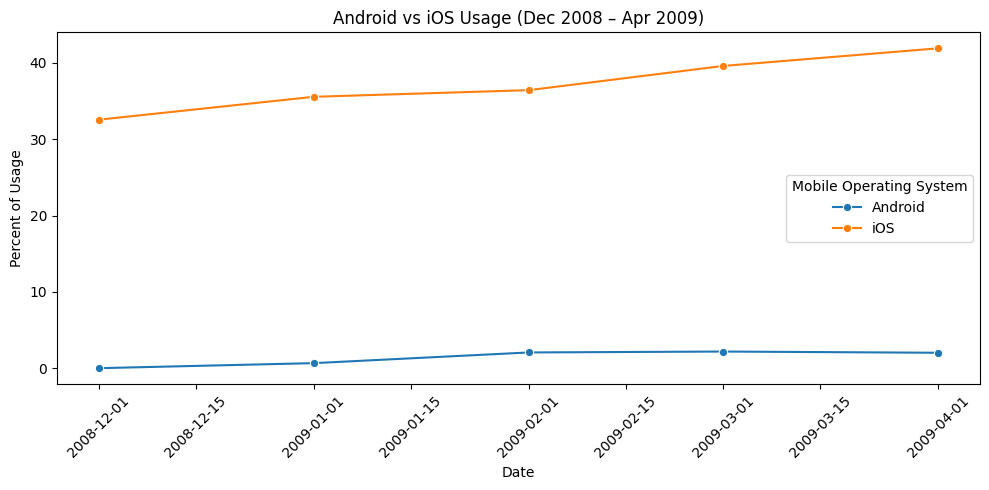

In [10]:
# Select Android and iOS records
mobile_trends = dated_df[
    dated_df["Mobile Operating System"].isin(["Android", "iOS"])
].copy()

# Create a line chart
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=mobile_trends,
    x="Date",
    y="Percent of Usage",
    hue="Mobile Operating System",
    marker="o"
)

plt.title("Android vs iOS Usage (Dec 2008 – Apr 2009)")
plt.xlabel("Date")
plt.ylabel("Percent of Usage")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

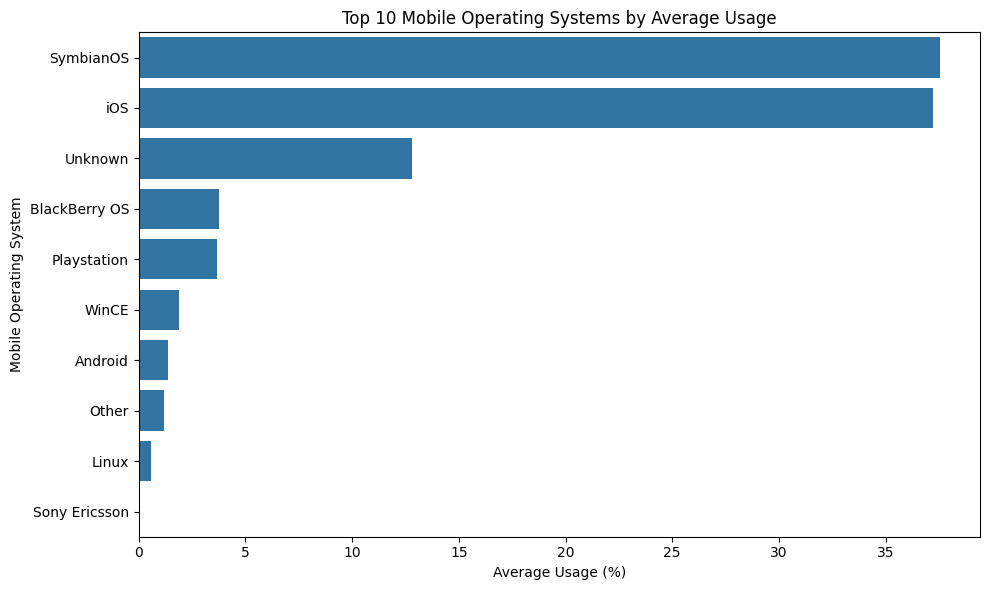

In [11]:
# Calculate average usage for each operating system
avg_usage = (
    dated_df.groupby("Mobile Operating System")["Percent of Usage"]
    .mean()
    .sort_values(ascending=False)
)

# Select the top 10 operating systems
top_10 = avg_usage.head(10).reset_index()

# Create a bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x="Percent of Usage",
    y="Mobile Operating System"
)

plt.title("Top 10 Mobile Operating Systems by Average Usage")
plt.xlabel("Average Usage (%)")
plt.ylabel("Mobile Operating System")
plt.tight_layout()
plt.show()

In [12]:
# Summary statistics for each operating system
summary_table = (
    dated_df.groupby("Mobile Operating System")["Percent of Usage"]
    .agg(["mean", "min", "max", "count"])
    .sort_values("mean", ascending=False)
    .round(2)
)

summary_table.columns = [
    "Average Usage (%)",
    "Minimum Usage (%)",
    "Maximum Usage (%)",
    "Number of Observations"
]

display(summary_table)

,Average Usage (%),Minimum Usage (%),Maximum Usage (%),Number of Observations
Mobile Operating System,,,,
SymbianOS,37.55,34.25,42.02,5
iOS,37.21,32.56,41.91,5
Unknown,12.82,10.20,16.00,5
BlackBerry OS,3.78,0.00,6.39,5
Playstation,3.68,2.85,4.47,5
WinCE,1.90,1.55,2.22,5
Android,1.38,0.00,2.18,5
Other,1.16,0.95,1.52,4
Linux,0.58,0.00,1.66,5


## Key Findings

1. SymbianOS recorded the highest average usage 37.55% among the dated observations.
2. iOS recorded the second-highest average usage 37.21% , increasing from 32.56% in December 2008 to 41.91% in April 2009.
3. Android usage increased from 0.00% in December 2008 to 2.02% in April 2009, after reaching 2.18% in March.
4. The dataset contains 1,898 rows, but only 126 have valid dates.
5. Missing dates and repeated records require careful investigation before drawing conclusions from the full dataset.

### Limitations

The dated observations cover December 2008 to April 2009 only. These results describe a limited historical sample, not current market share. The undated records require further investigation.

In [13]:
plt.savefig("../Images/android_vs_ios_usage.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [14]:
plt.savefig("../Images/top_10_mobile_os.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [15]:
from pathlib import Path

images_folder = Path("../Images")

print("Saved image files:")
for image_file in images_folder.glob("*.png"):
    print(image_file.name)

Saved image files:
top_10_mobile_os.png
android_vs_ios_usage.png


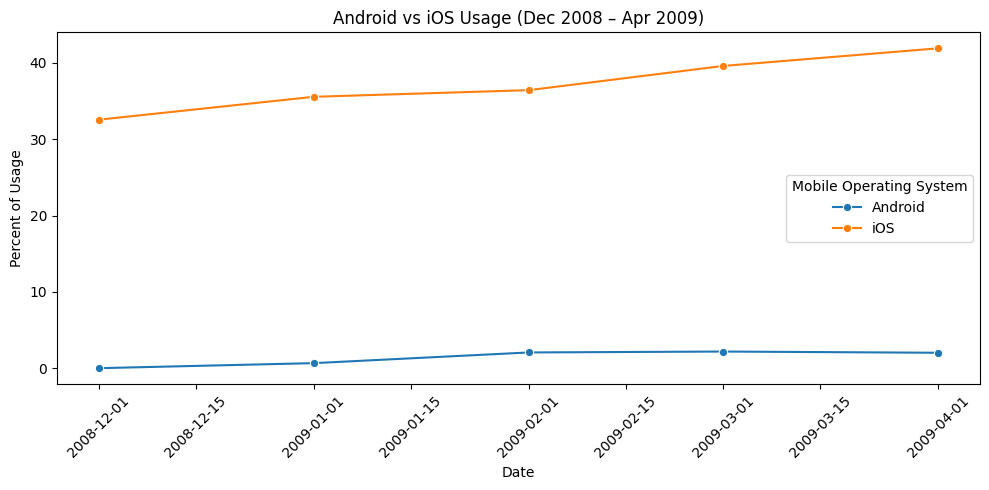

In [16]:
mobile_trends = dated_df[
    dated_df["Mobile Operating System"].isin(["Android", "iOS"])
].copy()

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=mobile_trends,
    x="Date",
    y="Percent of Usage",
    hue="Mobile Operating System",
    marker="o"
)

plt.title("Android vs iOS Usage (Dec 2008 – Apr 2009)")
plt.xlabel("Date")
plt.ylabel("Percent of Usage")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../Images/android_vs_ios_usage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

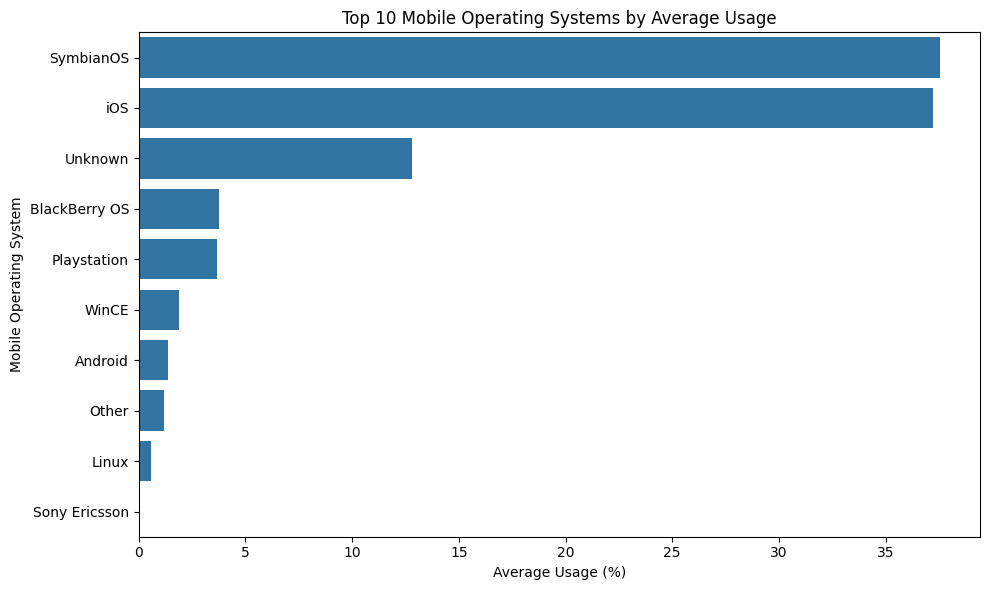

In [17]:
avg_usage = (
    dated_df.groupby("Mobile Operating System")["Percent of Usage"]
    .mean()
    .sort_values(ascending=False)
)

top_10 = avg_usage.head(10).reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x="Percent of Usage",
    y="Mobile Operating System"
)

plt.title("Top 10 Mobile Operating Systems by Average Usage")
plt.xlabel("Average Usage (%)")
plt.ylabel("Mobile Operating System")
plt.tight_layout()

plt.savefig(
    "../Images/top_10_mobile_os.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()